# Week 9 Recitation: Data Analysis

Keep the three data files beside this notebook. Solutions — run from top to bottom. Response times are in hours.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re

## Setup: Importing & Accessing Data

In [2]:
# Load both CSVs; use Order_ID and Ticket_ID as their indexes.
sales_data = pd.read_csv("ecommerce_sales_data.csv", index_col="Order_ID")
support_data = pd.read_csv("ecommerce_support_data.csv", index_col="Ticket_ID")

In [3]:
# Remove the supplied totals so we can calculate them in Task 2.
sales_data = sales_data.drop(columns="Total_Sale")
sales_data.head()

,Customer_ID,Product,Category,Order_Date,Quantity,Price
Order_ID,,,,,,
1,C045,Refrigerator,Electronics,2024-04-04,2,556
2,C048,Blender,Clothing,2024-03-07,3,648
3,C001,Refrigerator,Home & Kitchen,2024-01-02,4,211
4,C004,Blender,Electronics,2024-03-03,2,215
5,C004,Smartphone,Electronics,2024-03-08,4,327


In [4]:
sales_data.describe(include="all")

,Customer_ID,Product,Category,Order_Date,Quantity,Price
count,100,100,100,100,100.000000,100.000000
unique,41,7,4,64,NaN,NaN
top,C001,Refrigerator,Electronics,2024-04-07,NaN,NaN
freq,5,19,44,3,NaN,NaN
mean,NaN,NaN,NaN,NaN,2.410000,543.140000
std,NaN,NaN,NaN,NaN,1.064534,295.707405
min,NaN,NaN,NaN,NaN,1.000000,24.000000
25%,NaN,NaN,NaN,NaN,2.000000,299.750000
50%,NaN,NaN,NaN,NaN,2.000000,563.000000
75%,NaN,NaN,NaN,NaN,3.000000,824.000000


In [5]:
sales_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 1 to 100
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Customer_ID  100 non-null    str  
 1   Product      100 non-null    str  
 2   Category     100 non-null    str  
 3   Order_Date   100 non-null    str  
 4   Quantity     100 non-null    int64
 5   Price        100 non-null    int64
dtypes: int64(2), str(4)
memory usage: 4.8 KB


In [6]:
support_data.head()

,Customer_ID,Ticket_Date,Issue_Type,Resolution_Status,Response_Time
Ticket_ID,,,,,
T001,C002,2024-01-29,Delivery Delay,Resolved,32.0
T002,C005,2024-02-28,Payment Issue,Pending,NaN
T003,C014,2024-01-07,Technical Issue,Resolved,36.0
T004,C013,2024-02-18,Technical Issue,Resolved,9.0
T005,C028,2024-04-07,Product Issue,Pending,26.0


In [7]:
support_data.describe(include="all")

,Customer_ID,Ticket_Date,Issue_Type,Resolution_Status,Response_Time
count,100,100,100,100,58.000000
unique,38,61,4,2,NaN
top,C002,2024-03-18,Product Issue,Resolved,NaN
freq,7,4,28,52,NaN
mean,NaN,NaN,NaN,NaN,35.172414
std,NaN,NaN,NaN,NaN,21.564378
min,NaN,NaN,NaN,NaN,2.000000
25%,NaN,NaN,NaN,NaN,17.250000
50%,NaN,NaN,NaN,NaN,34.500000
75%,NaN,NaN,NaN,NaN,53.750000


In [8]:
support_data.info()

<class 'pandas.DataFrame'>
Index: 100 entries, T001 to T100
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Customer_ID        100 non-null    str    
 1   Ticket_Date        100 non-null    str    
 2   Issue_Type         100 non-null    str    
 3   Resolution_Status  100 non-null    str    
 4   Response_Time      58 non-null     float64
dtypes: float64(1), str(4)
memory usage: 4.7+ KB


In [9]:
# Select columns.
selected_columns = support_data[["Customer_ID", "Issue_Type", "Response_Time"]]
selected_columns.head()

,Customer_ID,Issue_Type,Response_Time
Ticket_ID,,,
T001,C002,Delivery Delay,32.0
T002,C005,Payment Issue,NaN
T003,C014,Technical Issue,36.0
T004,C013,Technical Issue,9.0
T005,C028,Product Issue,26.0


In [10]:
# .iloc selects rows by position.
first_n_rows = support_data.iloc[:5]
first_n_rows

,Customer_ID,Ticket_Date,Issue_Type,Resolution_Status,Response_Time
Ticket_ID,,,,,
T001,C002,2024-01-29,Delivery Delay,Resolved,32.0
T002,C005,2024-02-28,Payment Issue,Pending,NaN
T003,C014,2024-01-07,Technical Issue,Resolved,36.0
T004,C013,2024-02-18,Technical Issue,Resolved,9.0
T005,C028,2024-04-07,Product Issue,Pending,26.0


In [11]:
# .loc selects labels; both endpoints are included.
subset_data = support_data.loc["T006":"T016", ["Customer_ID", "Issue_Type", "Resolution_Status"]]
subset_data

,Customer_ID,Issue_Type,Resolution_Status
Ticket_ID,,,
T006,C002,Product Issue,Resolved
T007,C029,Delivery Delay,Resolved
T008,C007,Payment Issue,Pending
T009,C024,Delivery Delay,Pending
T010,C013,Delivery Delay,Pending
T011,C004,Delivery Delay,Pending
T012,C013,Technical Issue,Pending
T013,C001,Technical Issue,Resolved
T014,C014,Technical Issue,Resolved


## Task 1: Data Cleaning

In pandas 3, assign the filled column back to the DataFrame.

In [12]:
support_data["Response_Time"].isna().sum()

np.int64(42)

In [13]:
# Fill missing Response_Time values with the column mean.
support_data["Response_Time"] = support_data["Response_Time"].fillna(
    support_data["Response_Time"].mean()
)

In [14]:
support_data["Response_Time"].isna().sum()

np.int64(0)

## Task 2: Data Transformation & Filtering

In [15]:
# Create Total_Sale from Quantity * Price.
sales_data["Total_Sale"] = sales_data["Quantity"] * sales_data["Price"]

In [16]:
# Rate response times: <24 Good, 24–48 Average, >48 Poor.
def assign_rating(response_time):
    if response_time < 24:
        return "Good"
    elif response_time <= 48:
        return "Average"
    else:
        return "Poor"

In [17]:
support_data["Rating"] = support_data["Response_Time"].apply(assign_rating)
support_data.head()

,Customer_ID,Ticket_Date,Issue_Type,Resolution_Status,Response_Time,Rating
Ticket_ID,,,,,,
T001,C002,2024-01-29,Delivery Delay,Resolved,32.000000,Average
T002,C005,2024-02-28,Payment Issue,Pending,35.172414,Average
T003,C014,2024-01-07,Technical Issue,Resolved,36.000000,Average
T004,C013,2024-02-18,Technical Issue,Resolved,9.000000,Good
T005,C028,2024-04-07,Product Issue,Pending,26.000000,Average


In [18]:
sales_data.head()

,Customer_ID,Product,Category,Order_Date,Quantity,Price,Total_Sale
Order_ID,,,,,,,
1,C045,Refrigerator,Electronics,2024-04-04,2,556,1112
2,C048,Blender,Clothing,2024-03-07,3,648,1944
3,C001,Refrigerator,Home & Kitchen,2024-01-02,4,211,844
4,C004,Blender,Electronics,2024-03-03,2,215,430
5,C004,Smartphone,Electronics,2024-03-08,4,327,1308


In [19]:
# Keep only Electronics sales in electronics_sales.
electronics_sales = sales_data.loc[sales_data["Category"] == "Electronics"]
electronics_sales.head()

,Customer_ID,Product,Category,Order_Date,Quantity,Price,Total_Sale
Order_ID,,,,,,,
1,C045,Refrigerator,Electronics,2024-04-04,2,556,1112
4,C004,Blender,Electronics,2024-03-03,2,215,430
5,C004,Smartphone,Electronics,2024-03-08,4,327,1308
6,C040,Headphones,Electronics,2024-04-07,4,156,624
7,C010,Laptop,Electronics,2024-03-28,2,972,1944


## Task 3: Grouping, Aggregation & Plotting

In [20]:
# Sum Total_Sale by Category into category_sales_summary.
category_sales_summary = sales_data.groupby("Category")["Total_Sale"].sum()
category_sales_summary

Category
Clothing          19112
Electronics       60852
Footwear          25728
Home & Kitchen    28260
Name: Total_Sale, dtype: int64

In [21]:
# Group by Issue_Type; calculate Ticket_Count and Average_Response_Time in support_summary.
support_summary = support_data.groupby("Issue_Type").agg(
    Ticket_Count=("Response_Time", "size"),
    Average_Response_Time=("Response_Time", "mean"),
)
support_summary

,Ticket_Count,Average_Response_Time
Issue_Type,,
Delivery Delay,23,38.734633
Payment Issue,26,35.419098
Product Issue,28,33.216749
Technical Issue,23,33.712144


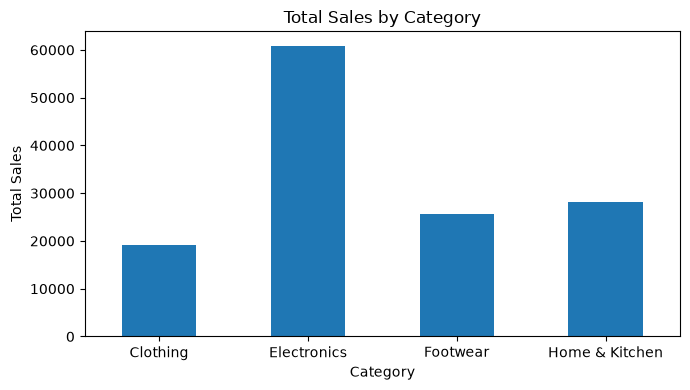

In [22]:
category_sales_summary.plot(kind="bar", figsize=(7, 4), rot=0)
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

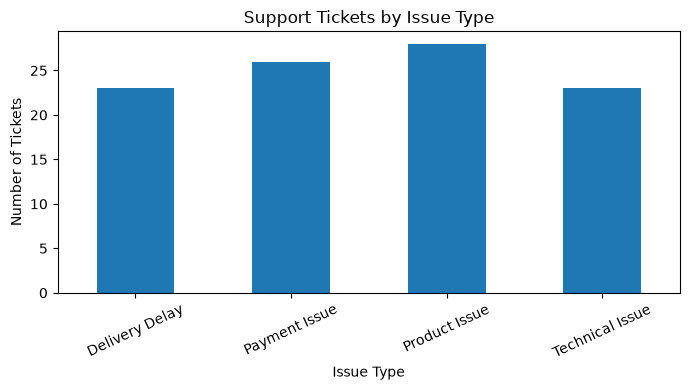

In [23]:
support_summary["Ticket_Count"].plot(kind="bar", figsize=(7, 4), rot=25)
plt.title("Support Tickets by Issue Type")
plt.xlabel("Issue Type")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

## Task 4: Regular Expressions

Use raw strings (`r"..."`) for the patterns.

In [24]:
with open("ecommerce_extended_data.txt", encoding="utf-8") as file:
    content = file.read()

In [25]:
# Match customer IDs such as C001.
customer_id_pattern = r"\bC\d{3}\b"
customer_ids = re.findall(customer_id_pattern, content)
print("Customer IDs:", customer_ids)

Customer IDs: ['C001', 'C002', 'C003', 'C004', 'C005', 'C006', 'C007', 'C008', 'C009', 'C010', 'C011', 'C012', 'C013', 'C014', 'C015', 'C016', 'C017', 'C018', 'C019', 'C020', 'C021', 'C022', 'C023', 'C024', 'C025', 'C026', 'C027', 'C028', 'C029', 'C030']


In [26]:
# Match phone numbers such as (123) 456-7890.
us_phone_pattern = r"\(\d{3}\) \d{3}-\d{4}"
phone_numbers = re.findall(us_phone_pattern, content)
print("Phone Numbers:", phone_numbers)

Phone Numbers: ['(555) 987-6543', '(202) 555-0143', '(415) 555-0199', '(650) 555-4321', '(212) 555-5678', '(718) 555-9876', '(323) 555-1234', '(213) 555-4567', '(202) 555-6789', '(917) 555-7890', '(310) 555-0145', '(646) 555-0199', '(510) 555-7777', '(212) 555-0123', '(415) 555-5678', '(617) 555-0245', '(415) 555-4567', '(408) 555-0150', '(213) 555-0188', '(718) 555-0199', '(626) 555-3333', '(646) 555-0178', '(505) 555-0177', '(408) 555-0145', '(323) 555-5678', '(808) 555-0138', '(323) 555-0129', '(702) 555-5678', '(416) 555-0188', '(202) 555-0190']


In [27]:
# Match the email addresses in the text.
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
emails = re.findall(email_pattern, content)
print("Emails:", emails)

Emails: ['john_doe45@example.com', 'jane.smith@retailstore.com', 'alex.brown@website.com', 'emily.jones@shoponline.com', 'michael_lee@retailmail.com', 'alice.wonder@webmail.org', 'robert_smith@businessmail.com', 'laura.baker@retailprovider.com', 'kevin.peters@example.net', 'andrew.jones@mailservice.com', 'diane.wood@supportemail.com', 'lucas.gray@onlineshop.com', 'simon.cook@ecommail.com', 'michael.scott@officeplace.com', 'linda.johnson@shopsupport.org', 'anna.morris@companysite.net', 'tony.stark@heroindustries.com', 'sara.conner@terminator.net', 'rebecca.white@marketplace.org', 'ryan.hall@webstore.com', 'emily.black@consumeremail.com', 'kevin.green@globalmail.net', 'thomas.clark@servicemail.org', 'matthew.cox@retailoutlet.com', 'alice.miller@shopsite.com', 'paul.morris@electronicsstore.com', 'emily.stone@fashionmail.org', 'support@servicecenter.com', 'charlie.brown@peanutsmail.com', 'mia.jones@bargainstore.org']
